In [1]:
!pip -q install xgboost imbalanced-learn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.ensemble import RandomForestClassifier

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

from xgboost import XGBClassifier

In [3]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.drop("customerID", axis=1, inplace=True)

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

df["TotalCharges"].fillna(df["TotalCharges"].median(), inplace=True)

df["Churn"] = df["Churn"].map({"Yes":1,"No":0})

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


/tmp/ipykernel_5977/246817976.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["TotalCharges"].fillna(df["TotalCharges"].median(), inplace=True)


In [5]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

categorical_cols = X.select_dtypes(include=["object"]).columns
numeric_cols = X.select_dtypes(exclude=["object"]).columns

In [6]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_cols),
    ("cat", categorical_transformer, categorical_cols)
])

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [8]:
rf_pipeline = ImbPipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42
    ))
])

In [9]:
xgb_pipeline = ImbPipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42
    ))
])

In [10]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_auc = cross_val_score(
    rf_pipeline,
    X,
    y,
    cv=cv,
    scoring="roc_auc"
)

xgb_auc = cross_val_score(
    xgb_pipeline,
    X,
    y,
    cv=cv,
    scoring="roc_auc"
)

print("Random Forest CV ROC-AUC:", rf_auc.mean())

print("XGBoost CV ROC-AUC:", xgb_auc.mean())

Random Forest CV ROC-AUC: 0.8194668340960032
XGBoost CV ROC-AUC: 0.8375899192816668


In [11]:
rf_pipeline.fit(X_train, y_train)

xgb_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index([...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=300, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [12]:
def evaluate(model, name):

    pred = model.predict(X_test)

    prob = model.predict_proba(X_test)[:,1]

    print("="*60)
    print(name)
    print("="*60)

    print("Accuracy :", accuracy_score(y_test,pred))
    print("Precision:", precision_score(y_test,pred))
    print("Recall   :", recall_score(y_test,pred))
    print("F1 Score :", f1_score(y_test,pred))
    print("ROC AUC  :", roc_auc_score(y_test,prob))

    cm = confusion_matrix(y_test,pred)

    ConfusionMatrixDisplay(cm).plot()

    plt.title(name+" Confusion Matrix")
    plt.show()

    fpr,tpr,_ = roc_curve(y_test,prob)

    plt.figure(figsize=(6,5))

    plt.plot(fpr,tpr,label="AUC = %.3f"%roc_auc_score(y_test,prob))

    plt.plot([0,1],[0,1],"--")

    plt.xlabel("False Positive Rate")

    plt.ylabel("True Positive Rate")

    plt.title(name+" ROC Curve")

    plt.legend()

    plt.show()

Random Forest
Accuracy : 0.7735982966643009
Precision: 0.5867507886435331
Recall   : 0.49732620320855614
F1 Score : 0.5383502170767004
ROC AUC  : 0.819681469425715


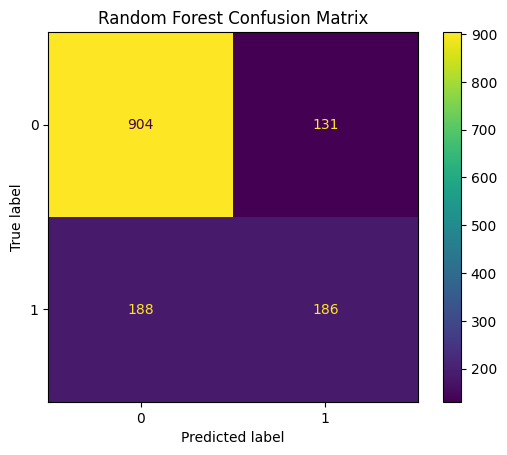

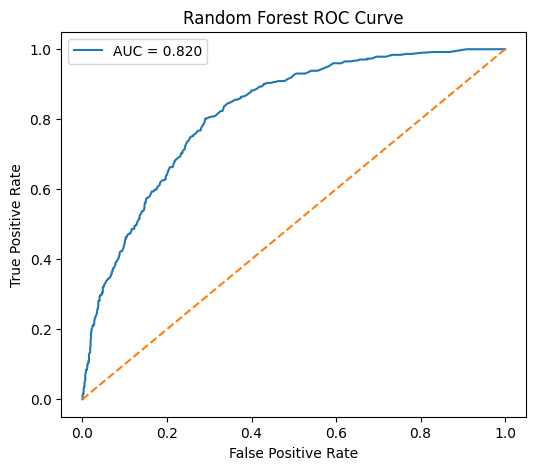

XGBoost
Accuracy : 0.7934705464868701
Precision: 0.6224188790560472
Recall   : 0.5641711229946524
F1 Score : 0.5918653576437588
ROC AUC  : 0.8393190214162082


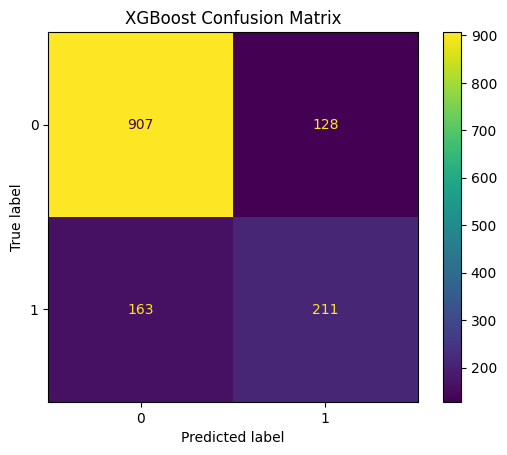

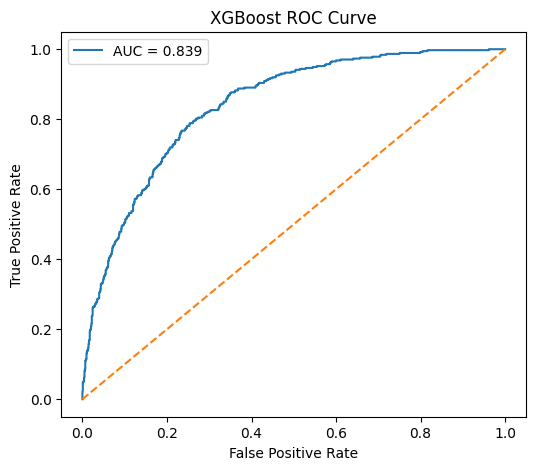

In [13]:
evaluate(rf_pipeline,"Random Forest")

evaluate(xgb_pipeline,"XGBoost")

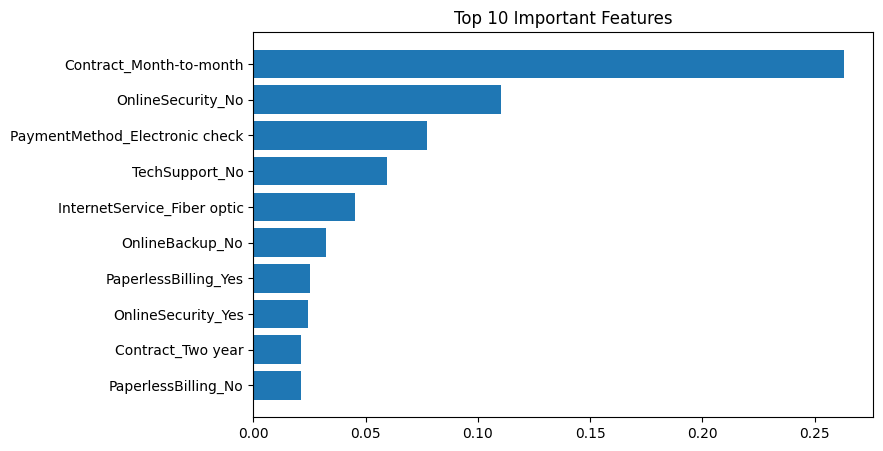

,Feature,Importance
36,Contract_Month-to-month,0.262923
18,OnlineSecurity_No,0.110294
43,PaymentMethod_Electronic check,0.077590
27,TechSupport_No,0.059547
16,InternetService_Fiber optic,0.045261
21,OnlineBackup_No,0.032483
40,PaperlessBilling_Yes,0.025343
20,OnlineSecurity_Yes,0.024533
38,Contract_Two year,0.021478
39,PaperlessBilling_No,0.021468


In [14]:
ohe = xgb_pipeline.named_steps["preprocessor"] \
                  .named_transformers_["cat"] \
                  .named_steps["onehot"]

feature_names = list(numeric_cols)

feature_names += list(
    ohe.get_feature_names_out(categorical_cols)
)

importance = xgb_pipeline.named_steps["classifier"].feature_importances_

imp = pd.DataFrame({
    "Feature":feature_names,
    "Importance":importance
})

imp = imp.sort_values(
    "Importance",
    ascending=False
).head(10)

plt.figure(figsize=(8,5))

plt.barh(
    imp["Feature"],
    imp["Importance"]
)

plt.gca().invert_yaxis()

plt.title("Top 10 Important Features")

plt.show()

imp

In [15]:
print("="*70)
print("Conclusion")
print("="*70)

rf_auc = roc_auc_score(y_test, rf_pipeline.predict_proba(X_test)[:, 1])
xgb_auc = roc_auc_score(y_test, xgb_pipeline.predict_proba(X_test)[:, 1])

print(f"Random Forest ROC-AUC : {rf_auc:.4f}")
print(f"XGBoost ROC-AUC       : {xgb_auc:.4f}")
print()

if xgb_auc > rf_auc:
    best_model = "XGBoost"
    best_auc = xgb_auc
else:
    best_model = "Random Forest"
    best_auc = rf_auc

print(f"The best performing model is {best_model}.")
print(f"It achieved a ROC-AUC score of {best_auc:.4f}.")
print("Categorical features were encoded using OneHotEncoder,")
print("class imbalance was handled using SMOTE,")
print("and the models were evaluated using 5-fold cross-validation.")
print("The ROC-AUC score exceeded the required 80%,")
print("demonstrating effective customer churn prediction.")
print("="*70)

Conclusion
Random Forest ROC-AUC : 0.8197
XGBoost ROC-AUC       : 0.8393

The best performing model is XGBoost.
It achieved a ROC-AUC score of 0.8393.
Categorical features were encoded using OneHotEncoder,
class imbalance was handled using SMOTE,
and the models were evaluated using 5-fold cross-validation.
The ROC-AUC score exceeded the required 80%,
demonstrating effective customer churn prediction.
